# Leakage and sensitivity check
**Jorlfran Torres · CAP 3764 · Fall 2026**

**Why this notebook exists:** in `04_modeling.ipynb` the random forest and gradient boosting models score
close to a perfect ROC-AUC of 1.0. Real credit-risk prediction is never that easy, so before reporting those
numbers we check whether `Financial_Risk_Label` was generated by a simple rule from a few features. If it
was, the models are rediscovering that rule (target leakage), not learning to predict risk.

**Questions**
1. Is the label rule-like? (`Debt_Equity_Ratio` ranges by class, a depth-2 decision tree)
2. Is `Total_Liabilities` a stand-in for `Debt_Equity_Ratio`?
3. How do the models perform after removing the suspect features?
4. Which result should the team report, and why?

Same split, models and metrics as notebook 04 (`risk_data.modeling`): stratified 80/20 split,
`random_state=42`, 5-fold stratified CV, PR-AUC as the main metric (the no-skill level equals the
at-risk rate, about 0.16).

Run **Kernel → Restart Kernel and Run All Cells** with the `Python (cap3764-risk)` kernel.
Requires `data/processed/cleaned_data.csv` (run `collect.py` then `clean.py`).

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.tree import DecisionTreeClassifier, export_text

from risk_data import modeling as m

warnings.filterwarnings("ignore", category=UserWarning)
sns.set_theme(style="whitegrid")

root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG_DIR = root / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

TARGET = m.TARGET
DER = "Debt_Equity_Ratio"
RULE_FEATURES = [DER, "Cash_Flow"]                 # the two features the rule seems to use
SUSPECT = [DER, "Cash_Flow", "Total_Liabilities"]  # plus the accounting proxy for debt-to-equity

## 1. Load data and split
Exactly the same loading and split as notebook 04, so the numbers are directly comparable.

In [2]:
df = m.load_model_data(root / "data" / "processed" / "cleaned_data.csv")
X, y = m.split_features(df)
X_train, X_test, y_train, y_test = m.make_train_test_split(X, y)

NO_SKILL = y_test.mean()  # PR-AUC of a model that guesses: the at-risk rate
pd.DataFrame({
    "rows": [len(y_train), len(y_test)],
    "at_risk_rate": [y_train.mean(), y_test.mean()],
}, index=["train", "test"]).round(3)

,rows,at_risk_rate
train,2860,0.161
test,715,0.161


## 2. Evidence 1: `Debt_Equity_Ratio` ranges by class
If the two classes overlap, no single cut-off separates them. If "not at risk" companies never go above
some value while at-risk ones do, the label behaves like a threshold rule.

In [4]:
ranges = df.groupby(TARGET)[DER].describe()[["count", "min", "25%", "50%", "75%", "max"]]
display(ranges.round(3))

safe_max = df.loc[df[TARGET] == 0, DER].max()
above = df[df[DER] > safe_max]
n_risk = (df[TARGET] == 1).sum()
print(f"Highest {DER} among 'not at risk' companies: {safe_max:.2f}")
print(f"Companies above that value: {len(above)}, at-risk share among them: {above[TARGET].mean():.1%}")
print(f"At-risk companies captured by this single cut-off: {(above[TARGET] == 1).sum()} of {n_risk} "
      f"({(above[TARGET] == 1).sum() / n_risk:.1%})")

,count,min,25%,50%,75%,max
Financial_Risk_Label,,,,,,
0,3000.0,0.00,0.22,0.59,1.21,2.50
1,575.0,0.01,2.58,2.92,3.39,3.99


Highest Debt_Equity_Ratio among 'not at risk' companies: 2.50
Companies above that value: 475, at-risk share among them: 100.0%
At-risk companies captured by this single cut-off: 475 of 575 (82.6%)


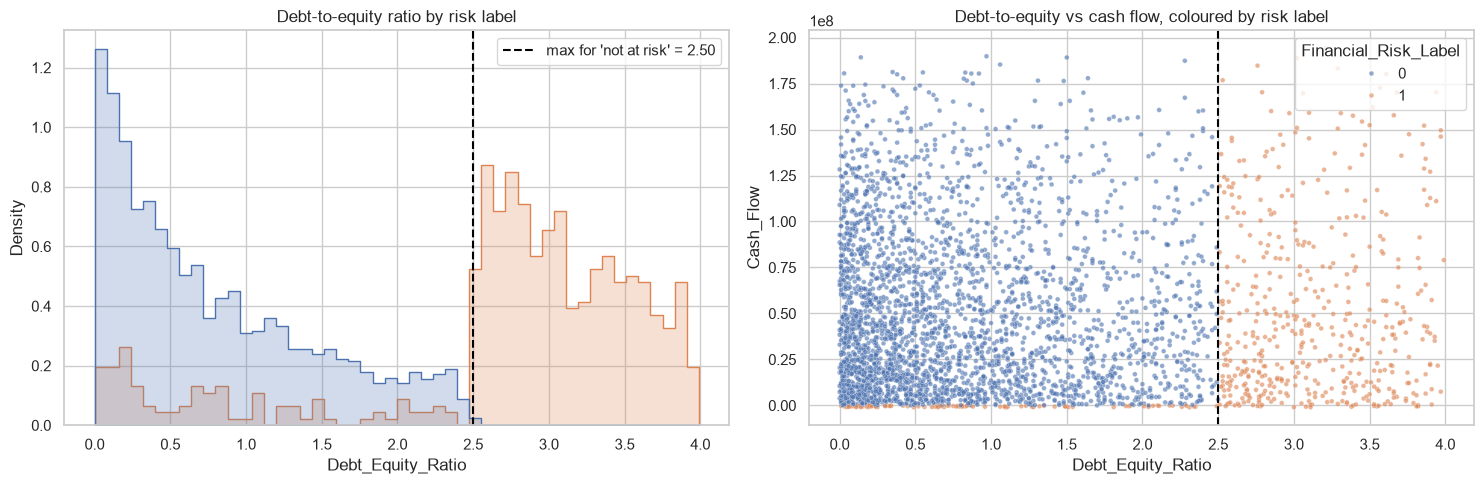

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.histplot(data=df, x=DER, hue=TARGET, bins=50, element="step", stat="density",
             common_norm=False, ax=axes[0])
axes[0].axvline(safe_max, color="black", linestyle="--", label=f"max for 'not at risk' = {safe_max:.2f}")
axes[0].set_title("Debt-to-equity ratio by risk label")
axes[0].set_xlabel("Debt_Equity_Ratio")
axes[0].legend()

sns.scatterplot(data=df, x=DER, y="Cash_Flow", hue=TARGET, s=12, alpha=0.6, ax=axes[1])
axes[1].axvline(safe_max, color="black", linestyle="--")
axes[1].set_title("Debt-to-equity vs cash flow, coloured by risk label")

fig.tight_layout()
fig.savefig(FIG_DIR / "leakage_rule_evidence.png", dpi=150)
plt.show()

**What this shows:** the two classes barely overlap on debt-to-equity. The highest `Debt_Equity_Ratio` among
"not at risk" companies is exactly **2.50**, and all **475** companies above 2.50 are at risk (100%). That single
cut-off captures **475 of 575** at-risk companies (**82.6%**). The middle 50% of safe companies sit between 0.22 and
1.21, while the middle 50% of at-risk companies sit between 2.58 and 3.39. A hard boundary at a round number like
2.50 is what a labelling rule looks like, not what real financial data looks like.

## 3. Evidence 2: a depth-2 decision tree
A tree with only two levels of splits is a rule of thumb ("if debt-to-equity > a and cash flow < b, then at
risk"). Real risk is too complex for that, so if such a tiny tree reproduces the label almost perfectly, the
label was most likely produced by a rule. Here accuracy means agreement with the label, not predictive skill.

In [6]:
def rule_check(features, name):
    """Fit a depth-2 tree on the training set and report how well it reproduces the test labels."""
    tree = DecisionTreeClassifier(max_depth=2, random_state=m.RANDOM_STATE)
    tree.fit(X_train[features], y_train)
    pred = tree.predict(X_test[features])
    print(f"--- {name} ---")
    print(export_text(tree, feature_names=list(features), decimals=2))
    return tree, {
        "agreement_with_label (accuracy)": accuracy_score(y_test, pred),
        "precision": precision_score(y_test, pred, zero_division=0),
        "recall": recall_score(y_test, pred, zero_division=0),
    }


numeric_cols = list(X_train.select_dtypes("number").columns)

_, rule_two = rule_check(RULE_FEATURES, "Depth-2 tree on Debt_Equity_Ratio + Cash_Flow")
free_tree, rule_all = rule_check(numeric_cols, "Depth-2 tree on all numeric features (it picks its own splits)")
chosen = sorted({numeric_cols[i] for i in free_tree.tree_.feature if i >= 0})
print("Features the unrestricted depth-2 tree chose:", chosen)

pd.DataFrame({"DER + Cash_Flow": rule_two, "all numeric": rule_all}).round(3)

--- Depth-2 tree on Debt_Equity_Ratio + Cash_Flow ---
|--- Debt_Equity_Ratio <= 2.50
|   |--- Cash_Flow <= 27866.62
|   |   |--- class: 1
|   |--- Cash_Flow >  27866.62
|   |   |--- class: 0
|--- Debt_Equity_Ratio >  2.50
|   |--- class: 1

--- Depth-2 tree on all numeric features (it picks its own splits) ---
|--- Debt_Equity_Ratio <= 2.50
|   |--- Cash_Flow <= 27866.62
|   |   |--- class: 1
|   |--- Cash_Flow >  27866.62
|   |   |--- class: 0
|--- Debt_Equity_Ratio >  2.50
|   |--- class: 1

Features the unrestricted depth-2 tree chose: ['Cash_Flow', 'Debt_Equity_Ratio']


,DER + Cash_Flow,all numeric
agreement_with_label (accuracy),1.0,1.0
precision,1.0,1.0
recall,1.0,1.0


**What this shows:** a tree with just two splits reproduces the label **perfectly** on the test set
(agreement, precision and recall all **1.00**). The rule it found is:

> **at risk** if `Debt_Equity_Ratio` > 2.50, **or** if `Debt_Equity_Ratio` ≤ 2.50 and `Cash_Flow` ≤ 27,866.62.

When the tree is free to choose from **all** numeric features, it picks exactly the same two,
`Debt_Equity_Ratio` and `Cash_Flow`, and the same thresholds. This is strong evidence that
`Financial_Risk_Label` was generated by this rule, so any model that sees these two features can "predict"
risk perfectly without learning anything about real companies.

## 4. Evidence 3: is `Total_Liabilities` a proxy for debt-to-equity?
By accounting, debt-to-equity = liabilities / (assets − liabilities). If the dataset follows that identity,
`Total_Liabilities` (together with `Total_Assets`) lets a model rebuild `Debt_Equity_Ratio` even after we
drop it. Spearman correlation is used because the relationship need not be linear.

In [7]:
equity = df["Total_Assets"] - df["Total_Liabilities"]
implied_der = (df["Total_Liabilities"] / equity).where(equity > 0)

pd.Series({
    "Spearman(Total_Liabilities, Debt_Equity_Ratio)": df["Total_Liabilities"].corr(df[DER], method="spearman"),
    "Spearman(L / (A - L), Debt_Equity_Ratio)": implied_der.corr(df[DER], method="spearman"),
    "rows with positive equity": (equity > 0).mean(),
}).round(3)

Spearman(Total_Liabilities, Debt_Equity_Ratio)    0.654
Spearman(L / (A - L), Debt_Equity_Ratio)          1.000
rows with positive equity                         1.000
dtype: float64

**What this shows:** `Total_Liabilities` on its own is only moderately related to debt-to-equity
(Spearman **0.654**). But liabilities / (assets − liabilities) matches `Debt_Equity_Ratio` **perfectly**
(Spearman **1.000**, and every row has positive equity). So `Debt_Equity_Ratio` is exactly computed from
`Total_Liabilities` and `Total_Assets`. If we drop debt-to-equity but keep both of those columns, a flexible model
can rebuild it, and the leak comes back. Section 6 tests whether that actually happens.

## 5. Sensitivity: the same models on three feature sets
We re-run notebook 04's cross-validation (training set) and test evaluation with:
1. **all features** (as in notebook 04),
2. **without `Debt_Equity_Ratio` and `Cash_Flow`** (the rule features),
3. **also without `Total_Liabilities`** (the accounting proxy).

Everything else is identical: same split, same folds, same pipelines (scaling and encoding fit on training
data only).

In [8]:
feature_sets = {
    "all features": [],
    "drop DER + Cash_Flow": RULE_FEATURES,
    "drop DER + Cash_Flow + Total_Liabilities": SUSPECT,
}

cv_parts, test_rows = [], []
for set_name, drop in feature_sets.items():
    Xtr, Xte = X_train.drop(columns=drop), X_test.drop(columns=drop)
    models = m.build_models(Xtr)
    cv_parts.append(m.cross_validate_models(models, Xtr, y_train).assign(feature_set=set_name))
    for model_name, model in models.items():
        model.fit(Xtr, y_train)
        test_rows.append({"feature_set": set_name, "model": model_name, **m.evaluate(model, Xte, y_test)})

cv_results = pd.concat(cv_parts).rename_axis("model").reset_index()
test_results = pd.DataFrame(test_rows)
order = list(feature_sets)

print("Cross-validation (training set), mean PR-AUC:")
display(cv_results.pivot(index="model", columns="feature_set", values="pr_auc_mean")[order].round(3))
print("Test set, PR-AUC:")
display(test_results.pivot(index="model", columns="feature_set", values="pr_auc")[order].round(3))

Cross-validation (training set), mean PR-AUC:


feature_set,all features,drop DER + Cash_Flow,drop DER + Cash_Flow + Total_Liabilities
model,,,
dummy,0.161,0.161,0.161
gradient_boosting,0.997,0.951,0.410
logistic_regression,0.886,0.821,0.323
random_forest,1.000,0.841,0.404


Test set, PR-AUC:


feature_set,all features,drop DER + Cash_Flow,drop DER + Cash_Flow + Total_Liabilities
model,,,
dummy,0.161,0.161,0.161
gradient_boosting,1.000,0.958,0.378
logistic_regression,0.890,0.791,0.342
random_forest,1.000,0.812,0.369


In [9]:
# Full test-set metrics for every model and feature set
test_results.set_index(["feature_set", "model"]).loc[order].round(3)

precision  \
feature_set                              model                            
all features                             dummy                    0.000   
                                         logistic_regression      0.671   
                                         random_forest            1.000   
                                         gradient_boosting        1.000   
drop DER + Cash_Flow                     dummy                    0.000   
                                         logistic_regression      0.488   
                                         random_forest            0.667   
                                         gradient_boosting        0.868   
drop DER + Cash_Flow + Total_Liabilities dummy                    0.000   
                                         logistic_regression      0.221   
                                         random_forest            0.535   
                                         gradient_boosting        0.394   

                                                              recall     f1  \
feature_set                              model                                
all features                             dummy                 0.000  0.000   
                                         logistic_regression   0.922  0.777   
                                         random_forest         1.000  1.000   
                                         gradient_boosting     0.991  0.996   
drop DER + Cash_Flow                     dummy                 0.000  0.000   
                                         logistic_regression   0.913  0.636   
                                         random_forest         0.765  0.713   
                                         gradient_boosting     0.913  0.890   
drop DER + Cash_Flow + Total_Liabilities dummy                 0.000  0.000   
                                         logistic_regression   0.522  0.311   
                                         random_forest         0.200  0.291   
                                         gradient_boosting     0.226  0.287   

                                                              roc_auc  pr_auc  
feature_set                              model                                 
all features                             dummy                  0.500   0.161  
                                         logistic_regression    0.968   0.890  
                                         random_forest          1.000   1.000  
                                         gradient_boosting      1.000   1.000  
drop DER + Cash_Flow                     dummy                  0.500   0.161  
                                         logistic_regression    0.923   0.791  
                                         random_forest          0.952   0.812  
                                         gradient_boosting      0.990   0.958  
drop DER + Cash_Flow + Total_Liabilities dummy                  0.500   0.161  
                                         logistic_regression    0.633   0.342  
                                         random_forest          0.607   0.369  
                                         gradient_boosting      0.607   0.378

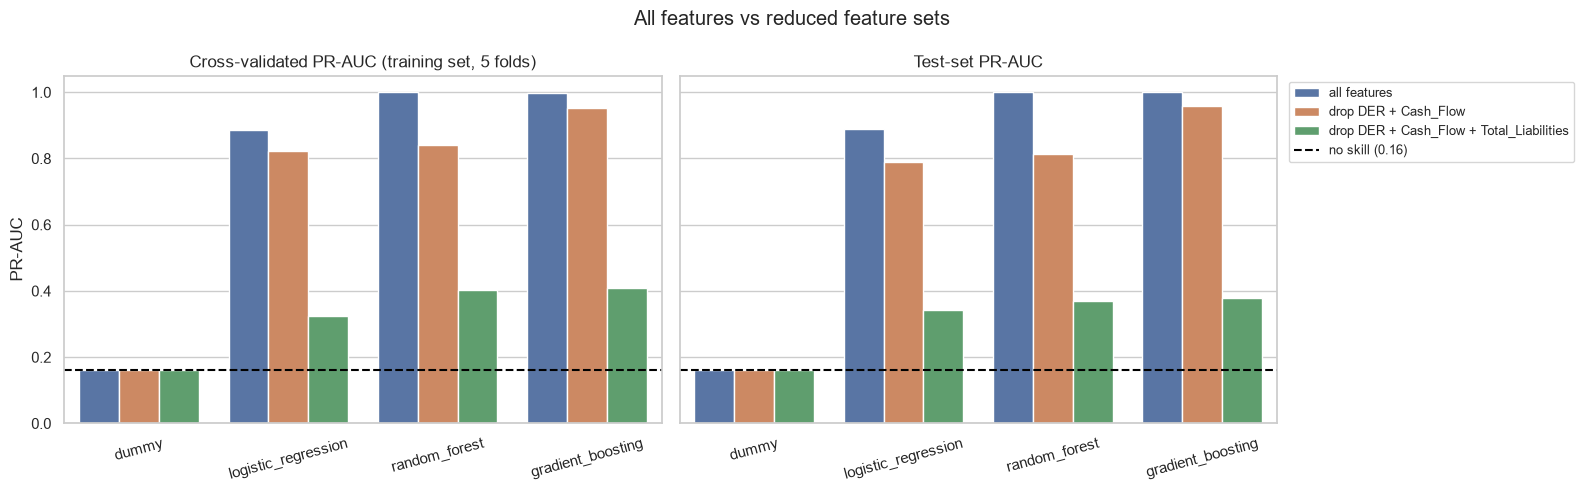

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)

sns.barplot(data=cv_results, x="model", y="pr_auc_mean", hue="feature_set", hue_order=order, ax=axes[0])
axes[0].set_title("Cross-validated PR-AUC (training set, 5 folds)")
axes[0].set_ylabel("PR-AUC")

sns.barplot(data=test_results, x="model", y="pr_auc", hue="feature_set", hue_order=order, ax=axes[1])
axes[1].set_title("Test-set PR-AUC")
axes[1].set_ylabel("")

for ax in axes:
    ax.axhline(NO_SKILL, color="black", linestyle="--", label=f"no skill ({NO_SKILL:.2f})")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=15)
axes[0].get_legend().remove()
axes[1].legend(fontsize=9, loc="upper left", bbox_to_anchor=(1.01, 1))  # one legend, outside the bars
axes[0].set_ylim(0, 1.05)

fig.suptitle("All features vs reduced feature sets")
fig.tight_layout()
fig.savefig(FIG_DIR / "leakage_sensitivity_pr_auc.png", dpi=150)
plt.show()

**What this shows:**
- **All features:** random forest and gradient boosting reach test PR-AUC **1.000** (CV 1.000 and 0.997), the same
  "too good" result as notebook 04.
- **Dropping only `Debt_Equity_Ratio` and `Cash_Flow` is not enough:** gradient boosting still scores test
  PR-AUC **0.958** (CV 0.951) and random forest **0.812**. The models are still mostly reproducing the rule
  (see section 6).
- **Also dropping `Total_Liabilities`:** test PR-AUC falls to **0.378** (gradient boosting), **0.369** (random
  forest) and **0.342** (logistic regression), against a no-skill level of **0.161**. In cross-validation:
  0.410, 0.404 and 0.323.
- These match the exploratory numbers in `docs/MODELING_NOTES.md` (about 0.32 for logistic regression and about
  0.41 for the tree models), so the earlier finding reproduces.

## 6. Is dropping `Total_Liabilities` needed, or are the first two features enough?
Two checks on the "drop DER + Cash_Flow" set:
- does removing `Total_Liabilities` as well change PR-AUC noticeably?
- can a depth-2 tree still rebuild the rule from the remaining features?

In [11]:
reduced_two = [c for c in numeric_cols if c not in RULE_FEATURES]
_, rule_reduced = rule_check(reduced_two, "Depth-2 tree after dropping DER + Cash_Flow")
display(pd.Series(rule_reduced).round(3))

pr = test_results.pivot(index="model", columns="feature_set", values="pr_auc")
cv_pr = cv_results.pivot(index="model", columns="feature_set", values="pr_auc_mean")
pd.DataFrame({
    "CV PR-AUC change from also dropping Total_Liabilities":
        cv_pr["drop DER + Cash_Flow + Total_Liabilities"] - cv_pr["drop DER + Cash_Flow"],
    "test PR-AUC change from also dropping Total_Liabilities":
        pr["drop DER + Cash_Flow + Total_Liabilities"] - pr["drop DER + Cash_Flow"],
}).round(3)

--- Depth-2 tree after dropping DER + Cash_Flow ---
|--- Return_on_Assets <= 0.00
|   |--- class: 1
|--- Return_on_Assets >  0.00
|   |--- Total_Liabilities <= 586214784.00
|   |   |--- class: 0
|   |--- Total_Liabilities >  586214784.00
|   |   |--- class: 1



agreement_with_label (accuracy)    0.880
precision                          0.796
recall                             0.339
dtype: float64

,CV PR-AUC change from also dropping Total_Liabilities,test PR-AUC change from also dropping Total_Liabilities
model,,
dummy,0.000,0.000
gradient_boosting,-0.541,-0.579
logistic_regression,-0.499,-0.449
random_forest,-0.437,-0.443


**What this shows: `Total_Liabilities` must be dropped as well.**
- Also removing it lowers PR-AUC by **0.44 to 0.58** for every model (test: −0.579 gradient boosting, −0.449
  logistic regression, −0.443 random forest; CV: −0.541, −0.499, −0.437). That is far too large to be noise:
  `Total_Liabilities` was carrying most of the rule, because with `Total_Assets` it rebuilds debt-to-equity
  exactly (section 4).
- A depth-2 tree on the remaining features no longer finds a clean rule. It uses `Return_on_Assets` ≤ 0 and
  `Total_Liabilities` > 586,214,784, and its recall is only **0.339** (agreement 0.880, precision 0.796). The
  ensemble models, however, can combine `Total_Liabilities` with `Total_Assets`, which a two-split tree cannot.
- **So dropping only the first two features is not enough.** The honest feature set removes all three.

## 7. Conclusions: which result to report

- **The label is rule-like:** every company with `Debt_Equity_Ratio` above 2.50 is at risk, and a two-split tree
  (`Debt_Equity_Ratio` > 2.50, or `Cash_Flow` ≤ 27,866.62) reproduces the test labels with 100% agreement.
- **All-features scores are not predictive performance:** the near-perfect PR-AUC/ROC-AUC (1.000) of the tree
  models in notebook 04 comes from rediscovering that rule, so it should not be presented as how well we can
  predict risk.
- **Report the reduced feature set without `Debt_Equity_Ratio`, `Cash_Flow` and `Total_Liabilities`.** Dropping
  only the first two still leaks the rule through `Total_Liabilities` + `Total_Assets` (test PR-AUC 0.958).
- **Honest performance:** best test PR-AUC **0.378** (gradient boosting; CV 0.410), vs a no-skill level of **0.161**.
  Logistic regression (0.342) and random forest (0.369) are close behind, and test ROC-AUC is only about 0.61 to 0.63.
  There is real but weak signal: the models do about 2.3× better than guessing at ranking at-risk companies, but
  are far from reliable.
- **Recommendation for 07 tuning, feature importance and the executive summary:** use the three-feature reduced
  set only, and quote the reduced numbers, not the all-features ones.

**Limitations**
- The dataset appears to be synthetic, with labels created by a rule, so even the reduced results may not
  transfer to real companies.
- Other columns could still carry traces of the rule (for example, cash flow may be partly predictable from income
  or revenue). This notebook only removes the three features with direct evidence.
- Results come from a single stratified split plus 5-fold CV with `random_state=42`; small differences
  (a few hundredths of PR-AUC, such as between the three reduced models) are within normal variation.
- At the default 0.5 threshold the reduced tree models have low recall (0.20 to 0.23), so a deployed model would
  need a lower threshold, which notebook 07 can explore.
- The depth-2 tree shows the label *can* be reproduced by a simple rule; it does not prove that this exact rule
  was used to create it.